# CoralNet near-duplicate review

Manual check of the **perceptual near duplicates** found by `mermaidseg.datasets.coralnet.dedup.near_duplicates`:
images that are not byte-identical but show the same picture (re-encoded, resized, re-cropped, colour-corrected or
rotated re-uploads), plus burst frames of the same scene.

**Only images still in the dataset are shown.** Copies in `configs/coralnet/image_blacklist.parquet` (byte-identical
duplicates, already removed) and the excluded low-quality sources are left out. That leaves **3,054 images in
2,416 pairs**, grouped into **1,301 groups** (images linked by any pair):

| | pairs | what it means |
|---|---|---|
| `near_dup` | 2,163 | verified score ≥ 0.6: same picture by the algorithm |
| `ambiguous` | 253 | score 0.4–0.6: could be a cropped copy or a different photo in the same rig |

Groups are numbered by priority: **cross-split** first (a leak between train / val / test), then **cross-source**,
then **same-source**; within each, groups with ambiguous pairs first.

**For each group** you get the images (lettered A, B, …, with source / image id, split, source name and pixel
size) and a table of its pairs (`G0001-1`, …) with the score, the RANSAC inliers and the pHash distance.
`r.zoom("G0001-1")` aligns the two images of a pair and shows where their fine detail differs:
a copy is dark everywhere (apart from compression noise), a different shot is bright where the content differs.

**Labelling**: section 1 is a labeller that goes through every pair, one at a time, starting at the first
unlabelled one. Click **Duplicate** (the same photo: copy, re-encode, crop, colour edit), **False positive** (not the
same photo, including a different shot of the same scene) or **Unsure** (to revisit). Each click is saved straight
away to `configs/coralnet/near_dup_labels.csv`, so you can stop at any time and rerun the cell to continue.
**Back** shows a labelled pair again; clicking a label overwrites it. **Group: rest dup** labels every unlabelled
pair of the current group as duplicate (for the groups of 5 copies, which have 10 pairs each).

The figure shows `a` and `b` as uploaded, `a` aligned onto `b`, and where their fine detail differs: a copy is dark
everywhere apart from compression noise, a different shot is bright wherever the content differs.

Sections 2–6 are for browsing whole groups.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import pandas as pd

from mermaidseg.datasets.coralnet.dedup.common import CONFIG_DIR
from mermaidseg.datasets.coralnet.dedup.near_dup_review import NearDupReview, PairLabeler, label_progress

pd.set_option("display.max_colwidth", 60)
r = NearDupReview()  # ~5 s
LABELS = CONFIG_DIR / "near_dup_labels.csv"

## Overview

Groups, images and pairs per category, and the images' splits. `r.groups` has one row per group; filter it directly
if `select` doesn't cover what you need.

In [2]:
display(r.overview())
r.groups.head(5)

,groups,images,pairs,ambiguous_pairs,test,train,val
category,,,,,,,
cross-split,2,4,2,0,2,0,2
cross-source,345,989,1225,15,2,987,0
same-source,954,2061,1189,238,610,991,460
total,1301,3054,2416,253,614,1978,462


,n_images,n_sources,n_splits,splits,sources,n_pairs,n_ambiguous,min_score,max_score,category,has_ambiguous
group,,,,,,,,,,,
G0001,2,2,2,test/val,"[4759, 4906]",1,0,0.820821,0.820821,cross-split,False
G0002,2,2,2,test/val,"[4759, 4906]",1,0,0.883656,0.883656,cross-split,False
G0003,2,2,1,train,"[4715, 4724]",1,1,0.427305,0.427305,cross-source,True
G0004,2,2,1,train,"[4715, 4724]",1,1,0.429320,0.429320,cross-source,True
G0005,2,2,1,train,"[4715, 4724]",1,1,0.444195,0.444195,cross-source,True


## 1. Label every pair

All 2,416 pairs in priority order (leaks first, then cross-source, then same-source). Rerun this cell to continue
where you stopped. To label only part, pass `pairs=`, e.g. the ambiguous ones:
`PairLabeler(r, LABELS, pairs=r.pairs.index[r.pairs["call"] == "ambiguous"].tolist())`.

In [3]:
labeler = PairLabeler(r, LABELS)
labeler.widget

In [ ]:
label_progress(r, LABELS)

## How to browse groups

- `r.page(k, per_page=5, **filters)`: page `k` (0-based) of the selected groups
- `r.select(...)` filters: `category="cross-source"` (or a list), `split="val"`, `sources=[4715, 4724]`,
  `ambiguous=True` (has an ambiguous pair) / `False`, `min_images=3`, `order="random"` with `seed`, `n=…`
- `r.show("G0042")`: one group; `max_images=None` / `max_rows=None` to see everything
- `r.zoom("G0042-1")`: aligned comparison of one pair

Output is kept small on purpose (JPEG figures, short tables). Clear old outputs before saving the notebook.

## 2. Cross-split (leaks between train / val / test)

Both images are in the dataset but in different splits. Two pairs, from the KAHO project (4759 val, 4906 test).

---
### G0001 · cross-split · 2 images · splits: test/val
Sources: 4759 (KAHO_Overlap_Plot), 4906 (KAHO_LTM). Pairs: 1 (0 ambiguous), score 0.82–0.82.

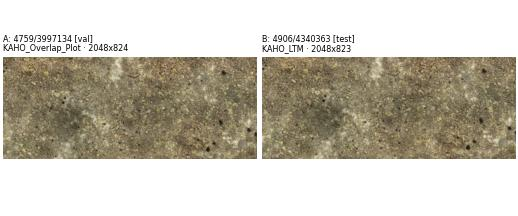

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0001-1,A–B,near_dup,0.821,657,6,False,4759/3997134,4906/4340363


---
### G0002 · cross-split · 2 images · splits: test/val
Sources: 4759 (KAHO_Overlap_Plot), 4906 (KAHO_LTM). Pairs: 1 (0 ambiguous), score 0.88–0.88.

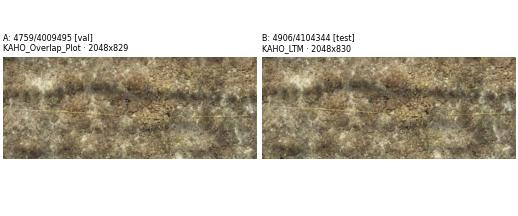

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0002-1,A–B,near_dup,0.884,939,8,False,4759/4009495,4906/4104344


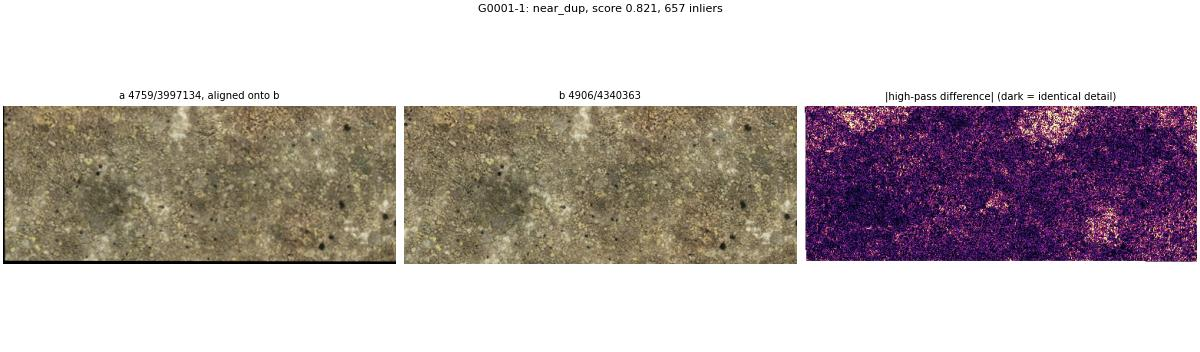

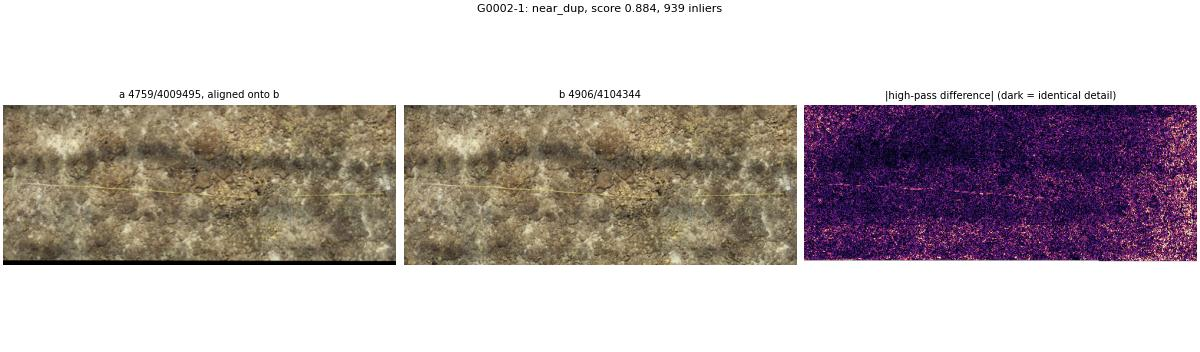

In [3]:
sel = r.select(category="cross-split")
r.show_many(sel)
for pair in r.pairs[r.pairs["group"].isin(sel.index)].index:
    r.zoom(pair)

## 3. Cross-source

The same picture in two or more sources of the same split. Not a leak, but counted twice (training weight, or
evaluation). Groups with ambiguous pairs come first. Increase the page number to go on.

Page 1/69 (345 groups)


---
### G0003 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.43–0.43.

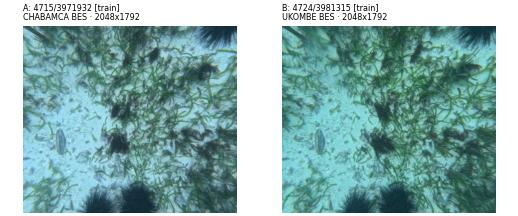

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0003-1,A–B,ambiguous,0.427,172,6,False,4715/3971932,4724/3981315


---
### G0004 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.43–0.43.

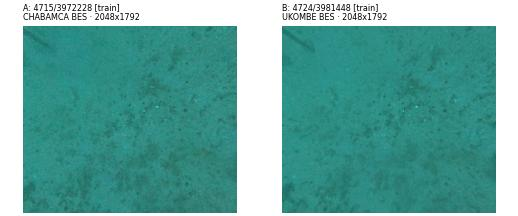

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0004-1,A–B,ambiguous,0.429,107,2,False,4715/3972228,4724/3981448


---
### G0005 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.44–0.44.

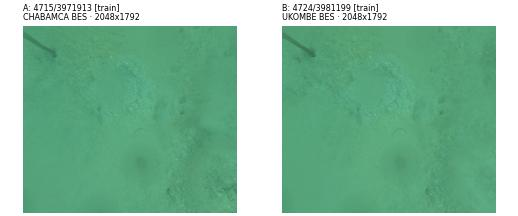

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0005-1,A–B,ambiguous,0.444,56,8,False,4715/3971913,4724/3981199


---
### G0006 · cross-source · 2 images · splits: test
Sources: 4909 (Tasmania_2023), 7212 (NSW_T2). Pairs: 1 (1 ambiguous), score 0.45–0.45.

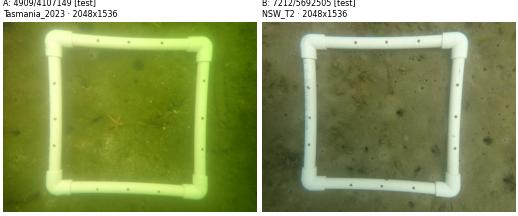

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0006-1,A–B,ambiguous,0.447,13,12,False,4909/4107149,7212/5692505


---
### G0007 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.50–0.50.

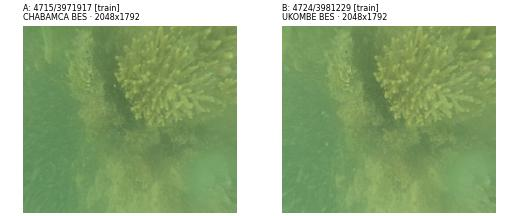

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0007-1,A–B,ambiguous,0.502,222,2,False,4715/3971917,4724/3981229


In [4]:
r.page(0, category="cross-source")

## 4. Same source

Mostly burst frames and re-edited versions inside one source. These matter mainly for val / test, where every copy
gets scored. Val / test first:

Page 1/41 (204 groups)


---
### G0348 · same-source · 47 images · splits: val
Sources: 23 (CVCE Bocas Del Toro Survey). Pairs: 74 (67 ambiguous), score 0.40–0.64.

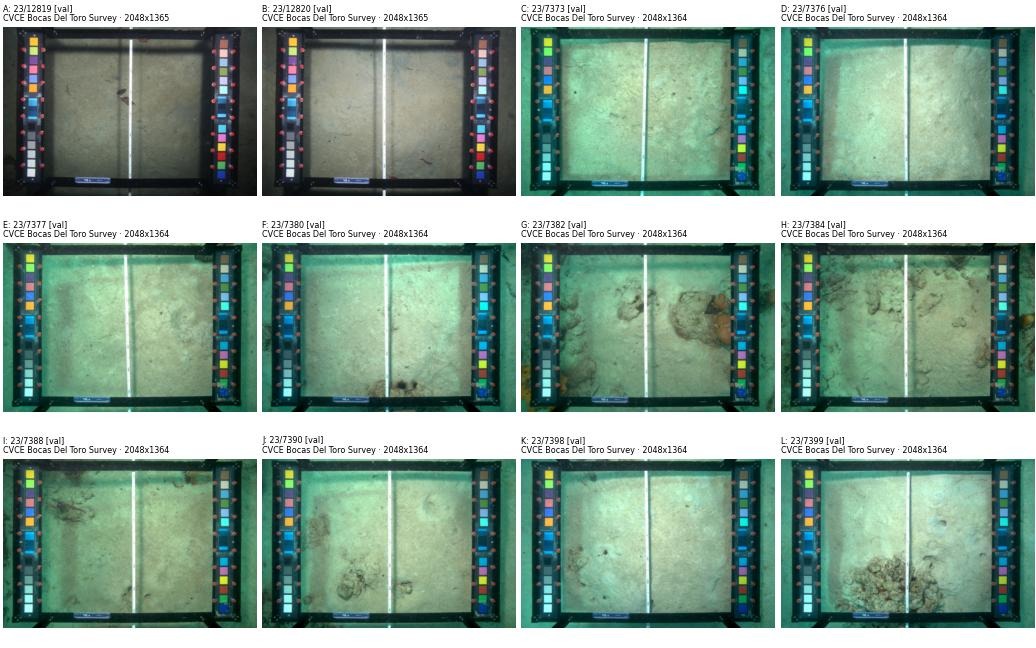

… 35 more images (show(..., max_images=None))


,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0348-1,P–X,near_dup,0.641,368,14,False,23/7404,23/7415
G0348-2,R–Y,near_dup,0.633,356,14,False,23/7407,23/7417
G0348-3,L–X,near_dup,0.628,260,14,False,23/7399,23/7415
G0348-4,U–W,near_dup,0.623,371,12,False,23/7411,23/7414
G0348-5,D–K,near_dup,0.617,319,14,False,23/7376,23/7398
G0348-6,P–AQ,near_dup,0.614,215,14,False,23/7404,23/7471
G0348-7,P–AP,near_dup,0.609,248,12,False,23/7404,23/7470
G0348-8,M–U,ambiguous,0.594,429,14,False,23/7400,23/7411
G0348-9,S–X,ambiguous,0.586,270,14,False,23/7408,23/7415


… 54 more pairs (show(..., max_rows=None))


---
### G0351 · same-source · 7 images · splits: val
Sources: 23 (CVCE Bocas Del Toro Survey). Pairs: 7 (7 ambiguous), score 0.40–0.47.

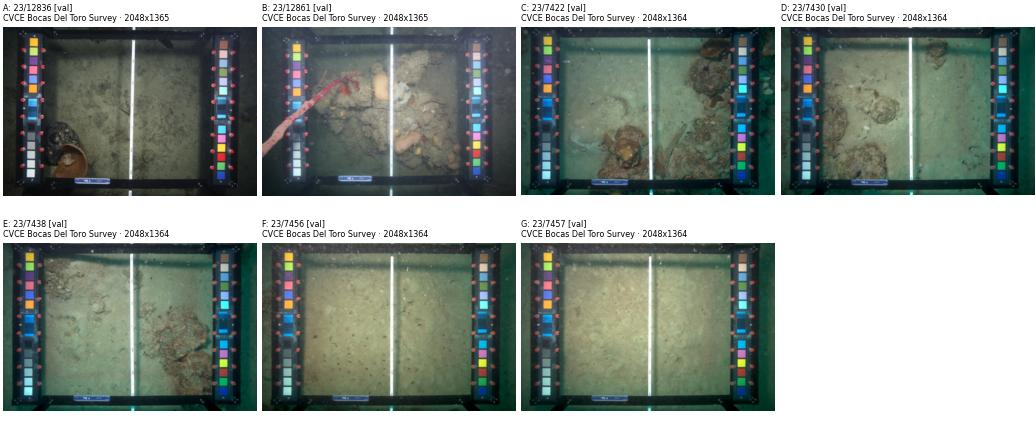

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0351-1,D–G,ambiguous,0.470,396,10,False,23/7430,23/7457
G0351-2,D–F,ambiguous,0.463,376,8,False,23/7430,23/7456
G0351-3,A–B,ambiguous,0.463,225,14,False,23/12836,23/12861
G0351-4,E–G,ambiguous,0.452,368,10,False,23/7438,23/7457
G0351-5,D–E,ambiguous,0.446,409,8,False,23/7430,23/7438
G0351-6,C–G,ambiguous,0.418,345,14,False,23/7422,23/7457
G0351-7,A–D,ambiguous,0.403,132,14,False,23/12836,23/7430


---
### G0353 · same-source · 4 images · splits: val
Sources: 23 (CVCE Bocas Del Toro Survey). Pairs: 5 (4 ambiguous), score 0.46–0.61.

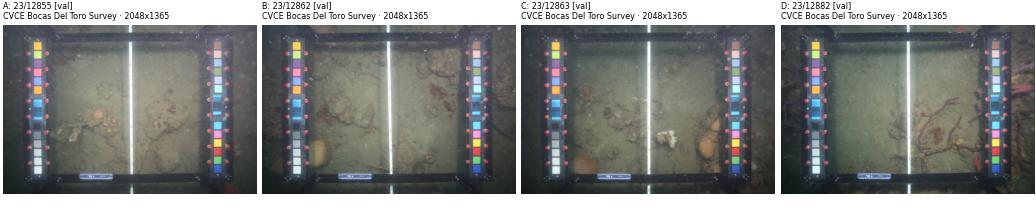

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0353-1,C–D,near_dup,0.615,498,14,False,23/12863,23/12882
G0353-2,A–D,ambiguous,0.590,485,12,False,23/12855,23/12882
G0353-3,A–C,ambiguous,0.496,538,10,False,23/12855,23/12863
G0353-4,A–B,ambiguous,0.470,581,10,False,23/12855,23/12862
G0353-5,B–D,ambiguous,0.459,521,14,False,23/12862,23/12882


---
### G0367 · same-source · 2 images · splits: val
Sources: 4596 (rare arrecifes 2023). Pairs: 1 (1 ambiguous), score 0.40–0.40.

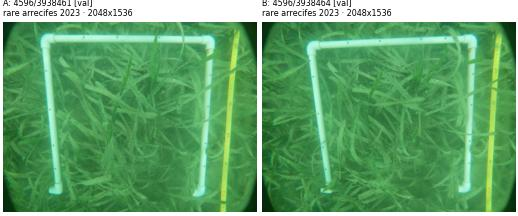

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0367-1,A–B,ambiguous,0.401,59,14,False,4596/3938461,4596/3938464


---
### G0369 · same-source · 2 images · splits: val
Sources: 23 (CVCE Bocas Del Toro Survey). Pairs: 1 (1 ambiguous), score 0.40–0.40.

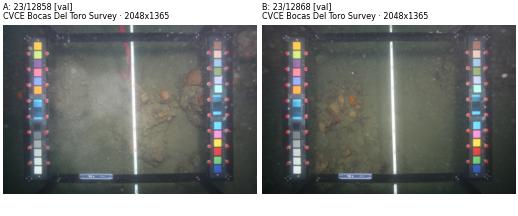

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0369-1,A–B,ambiguous,0.403,424,8,False,23/12858,23/12868


In [5]:
r.page(0, category="same-source", split="val")

Page 1/55 (275 groups)


---
### G0350 · same-source · 23 images · splits: test
Sources: 3722 (DLAB Tile Assessment). Pairs: 31 (27 ambiguous), score 0.40–0.69.

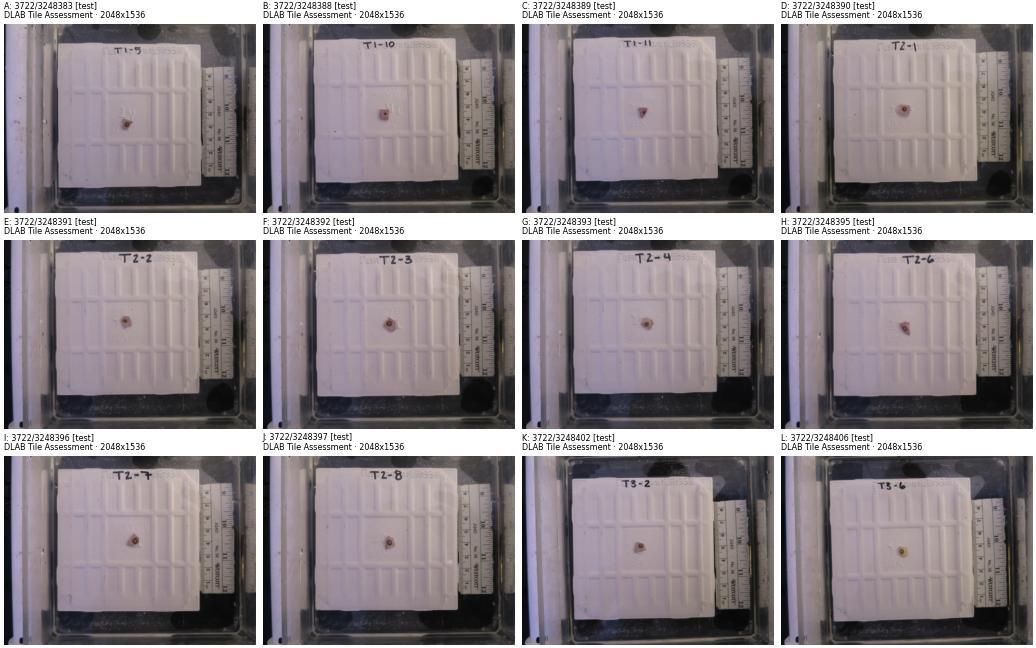

… 11 more images (show(..., max_images=None))


,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0350-1,N–O,near_dup,0.693,338,2,False,3722/3248408,3722/3248410
G0350-2,F–H,near_dup,0.663,406,2,False,3722/3248392,3722/3248395
G0350-3,H–I,near_dup,0.663,430,2,False,3722/3248395,3722/3248396
G0350-4,F–I,near_dup,0.658,343,4,False,3722/3248392,3722/3248396
G0350-5,M–N,ambiguous,0.598,381,4,False,3722/3248407,3722/3248408
G0350-6,R–W,ambiguous,0.596,266,12,False,3722/3248417,3722/3248435
G0350-7,N–Q,ambiguous,0.568,338,2,False,3722/3248408,3722/3248415
G0350-8,G–J,ambiguous,0.557,338,8,False,3722/3248393,3722/3248397
G0350-9,K–O,ambiguous,0.545,292,6,False,3722/3248402,3722/3248410


… 11 more pairs (show(..., max_rows=None))


---
### G0352 · same-source · 6 images · splits: test
Sources: 4909 (Tasmania_2023). Pairs: 5 (4 ambiguous), score 0.40–0.66.

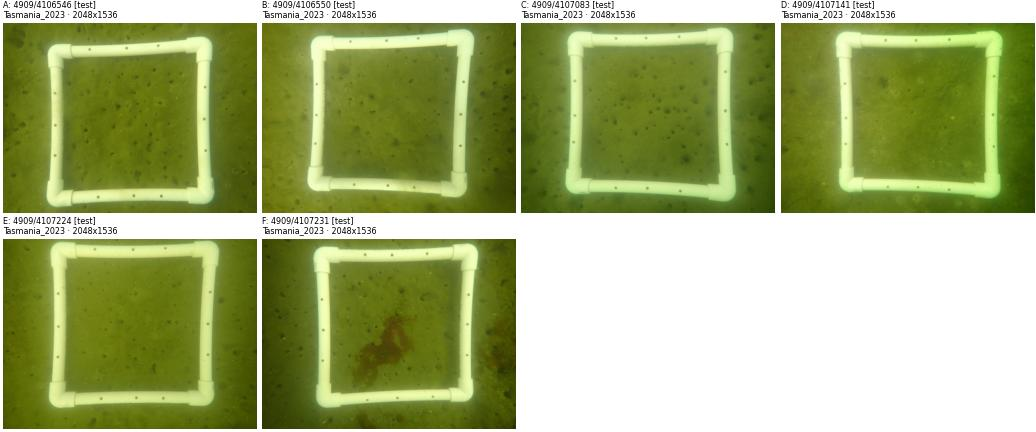

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0352-1,D–E,near_dup,0.664,12,12,False,4909/4107141,4909/4107224
G0352-2,C–E,ambiguous,0.527,13,12,False,4909/4107083,4909/4107224
G0352-3,B–C,ambiguous,0.451,19,12,False,4909/4106550,4909/4107083
G0352-4,D–F,ambiguous,0.405,9,12,False,4909/4107141,4909/4107231
G0352-5,A–F,ambiguous,0.403,12,14,True,4909/4106546,4909/4107231


---
### G0354 · same-source · 4 images · splits: test
Sources: 4311 (Ain Sukhna Sea Urchin and Cora). Pairs: 6 (4 ambiguous), score 0.47–0.71.

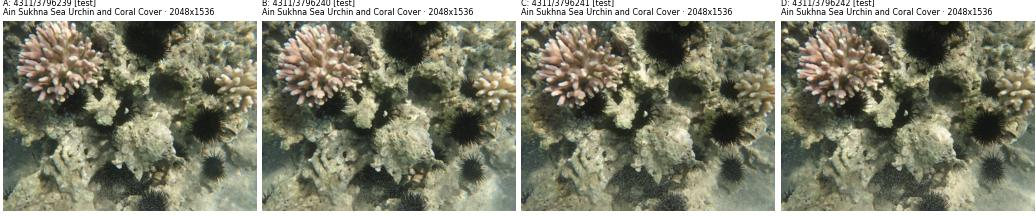

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0354-1,A–B,near_dup,0.709,489,10,False,4311/3796239,4311/3796240
G0354-2,C–D,near_dup,0.701,458,10,False,4311/3796241,4311/3796242
G0354-3,B–D,ambiguous,0.559,386,10,False,4311/3796240,4311/3796242
G0354-4,A–D,ambiguous,0.531,420,10,False,4311/3796239,4311/3796242
G0354-5,A–C,ambiguous,0.525,417,10,False,4311/3796239,4311/3796241
G0354-6,B–C,ambiguous,0.465,313,8,False,4311/3796240,4311/3796241


---
### G0355 · same-source · 4 images · splits: test
Sources: 4311 (Ain Sukhna Sea Urchin and Cora). Pairs: 6 (1 ambiguous), score 0.53–0.90.

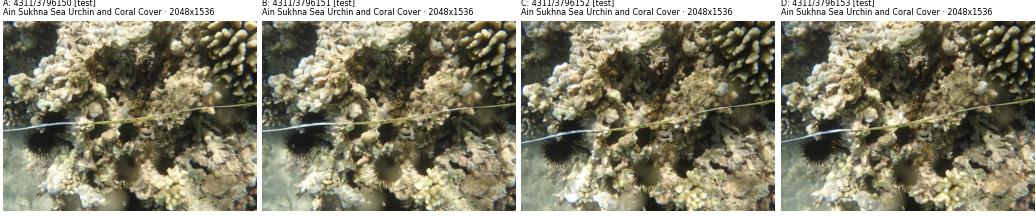

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0355-1,A–B,near_dup,0.903,663,6,False,4311/3796150,4311/3796151
G0355-2,C–D,near_dup,0.869,484,8,False,4311/3796152,4311/3796153
G0355-3,B–D,near_dup,0.635,368,12,False,4311/3796151,4311/3796153
G0355-4,A–C,near_dup,0.628,413,10,False,4311/3796150,4311/3796152
G0355-5,A–D,near_dup,0.624,394,12,False,4311/3796150,4311/3796153
G0355-6,B–C,ambiguous,0.531,388,14,False,4311/3796151,4311/3796152


---
### G0358 · same-source · 3 images · splits: test
Sources: 4311 (Ain Sukhna Sea Urchin and Cora). Pairs: 2 (1 ambiguous), score 0.46–0.63.

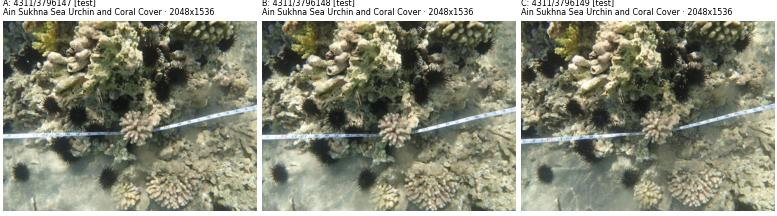

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0358-1,A–B,near_dup,0.625,619,4,False,4311/3796147,4311/3796148
G0358-2,B–C,ambiguous,0.461,398,8,False,4311/3796148,4311/3796149


In [6]:
r.page(0, category="same-source", split="test")

Page 1/95 (475 groups)


---
### G0349 · same-source · 25 images · splits: train
Sources: 4861 (Katalalixar). Pairs: 33 (33 ambiguous), score 0.40–0.48.

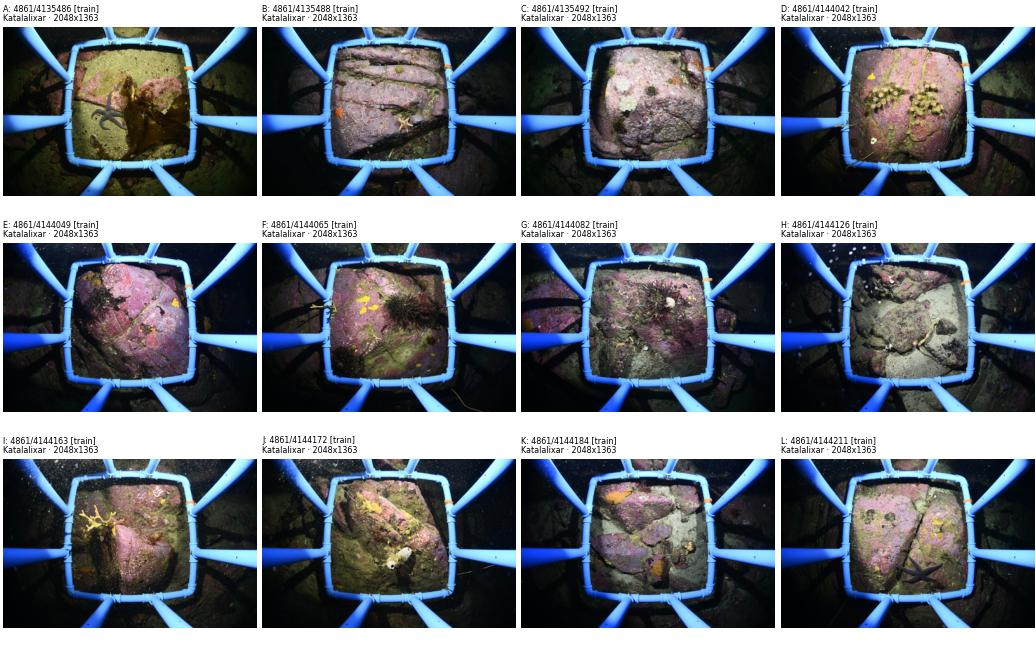

… 13 more images (show(..., max_images=None))


,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0349-1,K–L,ambiguous,0.485,153,4,False,4861/4144184,4861/4144211
G0349-2,W–Y,ambiguous,0.482,166,14,False,4861/4144482,4861/4144484
G0349-3,B–O,ambiguous,0.482,141,10,False,4861/4135488,4861/4144375
G0349-4,O–Y,ambiguous,0.463,193,12,False,4861/4144375,4861/4144484
G0349-5,V–Y,ambiguous,0.460,236,14,False,4861/4144481,4861/4144484
G0349-6,C–X,ambiguous,0.458,96,14,False,4861/4135492,4861/4144483
G0349-7,D–L,ambiguous,0.456,126,10,False,4861/4144042,4861/4144211
G0349-8,Q–T,ambiguous,0.455,94,12,False,4861/4144404,4861/4144474
G0349-9,B–D,ambiguous,0.455,79,14,False,4861/4135488,4861/4144042


… 13 more pairs (show(..., max_rows=None))


---
### G0356 · same-source · 4 images · splits: train
Sources: 6956 (REEFO_Test02). Pairs: 5 (1 ambiguous), score 0.60–0.70.

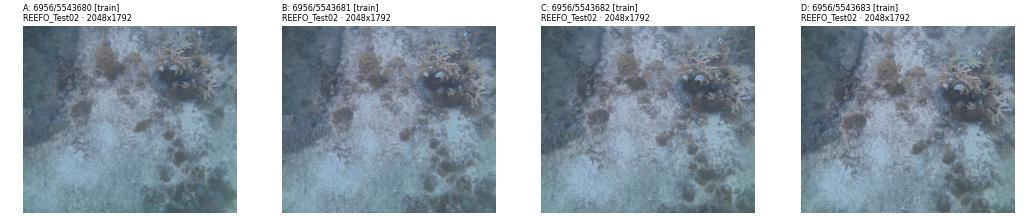

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0356-1,B–D,near_dup,0.696,739,14,False,6956/5543681,6956/5543683
G0356-2,A–C,near_dup,0.678,599,12,False,6956/5543680,6956/5543682
G0356-3,A–B,near_dup,0.637,664,8,False,6956/5543680,6956/5543681
G0356-4,B–C,near_dup,0.631,846,10,False,6956/5543681,6956/5543682
G0356-5,C–D,ambiguous,0.598,912,8,False,6956/5543682,6956/5543683


---
### G0357 · same-source · 3 images · splits: train
Sources: 6956 (REEFO_Test02). Pairs: 2 (1 ambiguous), score 0.41–0.79.

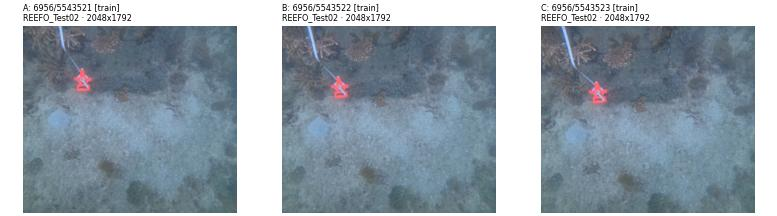

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0357-1,A–B,near_dup,0.791,398,12,False,6956/5543521,6956/5543522
G0357-2,B–C,ambiguous,0.412,408,6,False,6956/5543522,6956/5543523


---
### G0359 · same-source · 3 images · splits: train
Sources: 6956 (REEFO_Test02). Pairs: 2 (2 ambiguous), score 0.53–0.53.

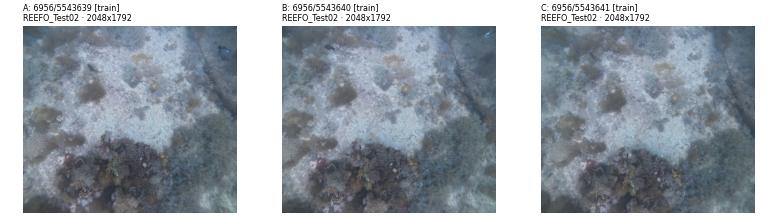

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0359-1,A–C,ambiguous,0.535,558,14,False,6956/5543639,6956/5543641
G0359-2,B–C,ambiguous,0.530,689,14,False,6956/5543640,6956/5543641


---
### G0360 · same-source · 3 images · splits: train
Sources: 3440 (PELD-Iloc - Noronha). Pairs: 2 (1 ambiguous), score 0.53–0.70.

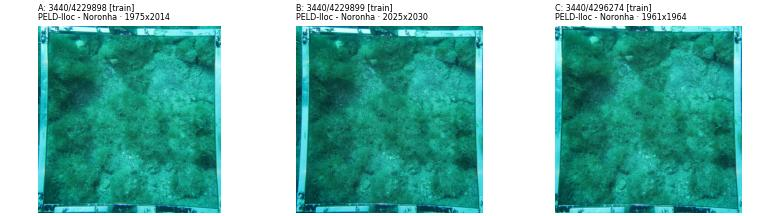

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0360-1,A–C,near_dup,0.699,881,8,False,3440/4229898,3440/4296274
G0360-2,A–B,ambiguous,0.532,722,4,False,3440/4229898,3440/4229899


In [7]:
r.page(0, category="same-source", split="train")

## 5. Ambiguous pairs only

Score 0.4–0.6: the algorithm couldn't decide. Use `zoom` on the pairs.

Page 1/23 (112 groups)


---
### G0003 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.43–0.43.

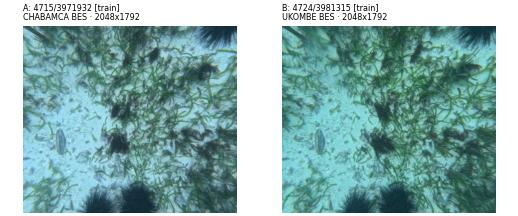

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0003-1,A–B,ambiguous,0.427,172,6,False,4715/3971932,4724/3981315


---
### G0004 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.43–0.43.

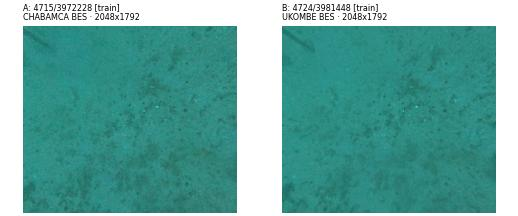

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0004-1,A–B,ambiguous,0.429,107,2,False,4715/3972228,4724/3981448


---
### G0005 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.44–0.44.

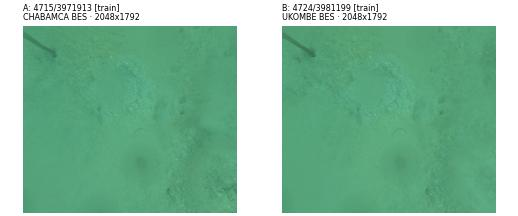

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0005-1,A–B,ambiguous,0.444,56,8,False,4715/3971913,4724/3981199


---
### G0006 · cross-source · 2 images · splits: test
Sources: 4909 (Tasmania_2023), 7212 (NSW_T2). Pairs: 1 (1 ambiguous), score 0.45–0.45.

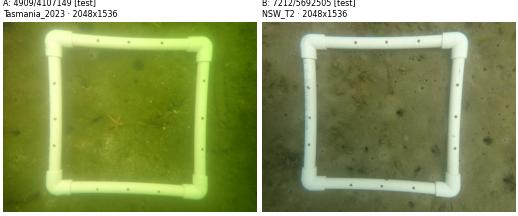

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0006-1,A–B,ambiguous,0.447,13,12,False,4909/4107149,7212/5692505


---
### G0007 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.50–0.50.

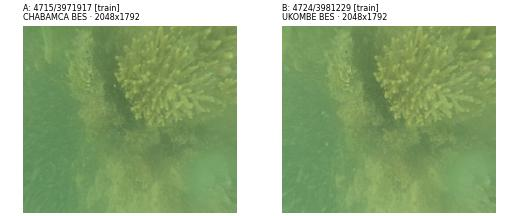

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0007-1,A–B,ambiguous,0.502,222,2,False,4715/3971917,4724/3981229


In [8]:
r.page(0, ambiguous=True)

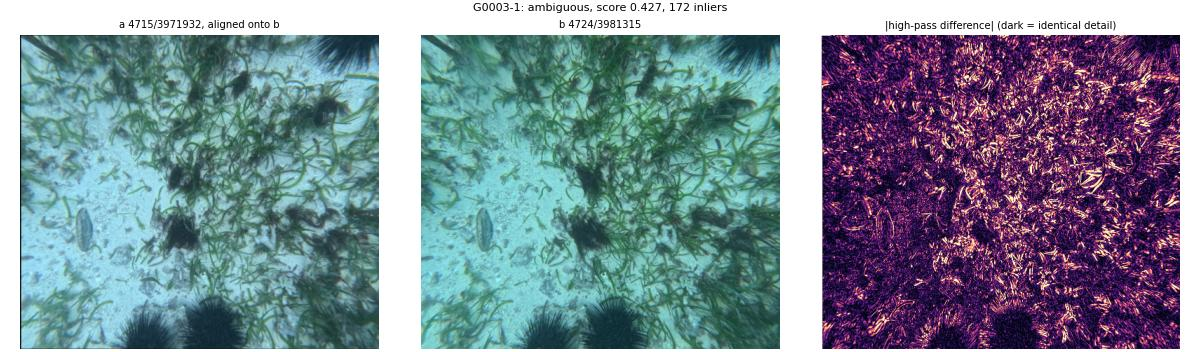

In [9]:
r.zoom(r.pairs[r.pairs["call"] == "ambiguous"].index[0])

## 6. Lookups

A random sample (to estimate how often the algorithm's call is right), one source, or a specific group or pair.

---
### G0581 · same-source · 2 images · splits: test
Sources: 4311 (Ain Sukhna Sea Urchin and Cora). Pairs: 1 (0 ambiguous), score 0.74–0.74.

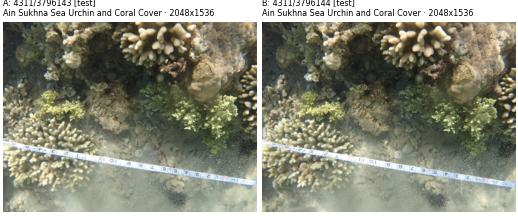

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0581-1,A–B,near_dup,0.743,525,10,False,4311/3796143,4311/3796144


---
### G1017 · same-source · 2 images · splits: val
Sources: 3567 (Tonga_2022-08 & Samoa_2022-09 ). Pairs: 1 (0 ambiguous), score 1.00–1.00.

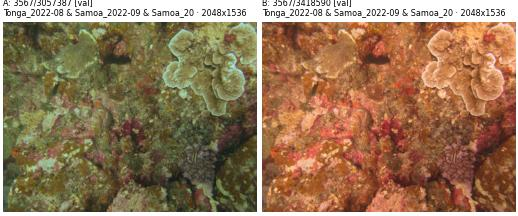

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G1017-1,A–B,near_dup,0.999,1792,0,False,3567/3057387,3567/3418590


---
### G0762 · same-source · 2 images · splits: train
Sources: 6218 (private/deleted). Pairs: 1 (0 ambiguous), score 0.90–0.90.

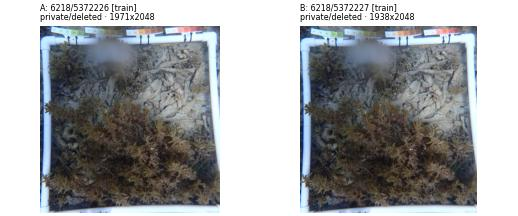

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0762-1,A–B,near_dup,0.901,1115,2,False,6218/5372226,6218/5372227


In [10]:
r.show_many(r.select(order="random", seed=0, n=3))

---
### G0003 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.43–0.43.

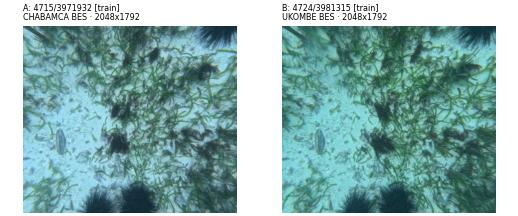

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0003-1,A–B,ambiguous,0.427,172,6,False,4715/3971932,4724/3981315


---
### G0004 · cross-source · 2 images · splits: train
Sources: 4715 (CHABAMCA BES), 4724 (UKOMBE BES). Pairs: 1 (1 ambiguous), score 0.43–0.43.

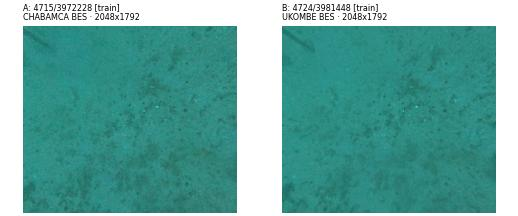

,images,call,score,inliers,phash_dist,rotated,a,b
pair,,,,,,,,
G0004-1,A–B,ambiguous,0.429,107,2,False,4715/3972228,4724/3981448


In [11]:
r.show_many(r.select(sources=[4715, 4724], n=2))